In [46]:
import numpy as np
import matplotlib.pyplot as plt

def sigm(z):
    return 1 / (1 + np.exp(-z))

class LogisticRegression():

    def fit(self, X, y):
        rng = np.random.default_rng(42)

        self.w = rng.random((X.shape[1],))
        alpha = 0.5
        steps = 2000

        for step in range(steps):
            self.w = self.w + alpha * X.T @ (y - sigm(X @ self.w))

        return self

    def predict(self, X):
        return (sigm(X @ self.w) >= 0.5).astype(int)


In [47]:
rng = np.random.default_rng(37)
X = rng.uniform(0, 6, (200, 2))
better_X = np.column_stack([np.ones(X.shape[0]), X])
y = ((better_X[:,1] + better_X[:,2]) > 6).astype(int)

model = LogisticRegression().fit(better_X,y)



/tmp/ipykernel_4711/533380334.py:5: RuntimeWarning: overflow encountered in exp
  return 1 / (1 + np.exp(-z))


/tmp/ipykernel_4711/533380334.py:5: RuntimeWarning: overflow encountered in exp
  return 1 / (1 + np.exp(-z))


(0.0, 6.0)

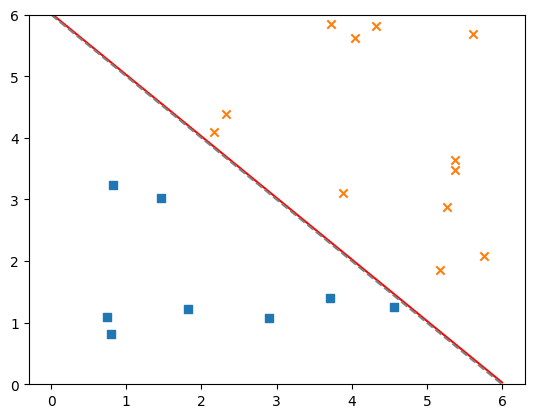

In [48]:
X_test = np.column_stack([np.ones(20,), rng.uniform(0,6,(20,2))])
y = model.predict(X_test)
class_0 = y == 0
class_1 = y == 1

plt.scatter(X_test[class_0,1], X_test[class_0,2], marker='s')
plt.scatter(X_test[class_1, 1], X_test[class_1, 2], marker='x')
line = np.linspace(0, 6, 200)
w = model.w
plt.plot(line, -(w[0] + w[1] * line) / w[2], color='red')
plt.plot(line, 6 - line, color='gray', linestyle='--')
plt.ylim(0, 6)
